# Etapa 2 · 02 — Análisis exploratorio (EDA)
Dataset: `output/dataset_analitico.parquet` (1 fila por orden entregada).

**Preguntas guía** (derivadas de las preguntas analíticas de Etapa 1):
1. ¿Cómo se distribuyen los tiempos de entrega y la demora real?
2. ¿Qué factores (reales y simulados) se asocian a la demora real y cuánto separan las entregas tardías de las puntuales?
3. ¿Cómo impacta la demora en la satisfacción del cliente?
4. ¿Hay estacionalidad? ¿Qué estados/segmentos concentran el problema?

> **Advertencia metodológica (flota sintética):** las variables de Olist (fechas, reseñas, fletes, estados) son **reales**. En la flota, `distance_km`, `delivery_status` y `eta_variation_hours` **derivan de datos reales**; `traffic_*`, `weather_*`, `route_risk_*`, `driver_*`, incidentes y mantenimiento son **simulados y condicionados a la realidad** (copula gaussiana con marginales de Kaggle). Sus asociaciones con la demora real están **impuestas por diseño**: describen el sistema simulado, no el mundo. Los hallazgos sobre Olist (demora, estados, reseñas) sí son empíricos. `delivery_status` replica la demora real; en todo el notebook la demora es `demora_olist`.

In [1]:
import pathlib, warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ROOT = pathlib.Path(".."); FIG = ROOT/"figures"; FIG.mkdir(exist_ok=True)
df = pd.read_parquet(ROOT/"output"/"dataset_analitico.parquet")
def save(name): plt.tight_layout(); plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); plt.show()
print(df.shape); df.head(3).T

(96281, 55)


,0,1,2
order_id,bfbd0f9bdef84302105ad712db648a6c,676157c2d1075c88ea0009f8d7d2d389,9d664ec86be69d869bb6870294c4fdd8
delivery_id,29810,68840,95542
fecha_compra,2016-09-15 12:16:38,2016-10-07 10:18:50,2016-10-08 15:02:10
mes_compra,2016-09-01 00:00:00,2016-10-01 00:00:00,2016-10-01 00:00:00
anio,2016,2016,2016
mes,9,10,10
dia_semana,4,5,6
estado_origen,PR,PR,SP
estado_destino,SP,AL,BA
mismo_estado,False,False,False


## 1. Panorama general y calidad del dataset final

In [2]:
num = ["dias_entrega_total","dias_hasta_despacho","dias_transito","dias_prometidos","dias_demora_olist",
       "eta_variation_hours","distance_km","distancia_haversine_km","flete_total","precio_total","peso_total_g",
       "traffic_congestion_level","weather_condition_severity","route_risk_level","loading_unloading_time_h",
       "driver_behavior_score","indice_fatiga","review_score"]
desc = df[num].describe(percentiles=[.05,.25,.5,.75,.95]).T
desc["cv"] = desc["std"]/desc["mean"].abs()                 # coeficiente de variación
desc["asimetria"] = df[num].skew(); desc["curtosis"] = df[num].kurt()
desc.round(3)

,count,mean,std,min,5%,25%,50%,75%,95%,max,cv,asimetria,curtosis
dias_entrega_total,96281.0,12.568,9.550,0.53,3.020,6.780,10.230,15.730,29.290,209.630,0.760,3.834,39.318
dias_hasta_despacho,96281.0,3.233,3.552,0.00,0.460,1.130,2.200,4.070,8.870,125.780,1.098,4.920,58.039
dias_transito,96281.0,9.335,8.747,0.00,1.120,4.100,7.100,12.030,24.220,205.190,0.937,4.505,52.076
dias_prometidos,96281.0,23.737,8.756,2.01,10.480,18.330,23.230,28.410,38.420,155.140,0.369,0.904,4.298
dias_demora_olist,96281.0,-11.169,10.184,-146.02,-25.780,-16.240,-11.930,-6.390,3.820,188.980,0.912,2.017,28.091
eta_variation_hours,96281.0,31.957,118.900,-168.00,-117.560,-42.400,0.010,81.770,336.000,336.000,3.721,1.049,0.651
distance_km,96281.0,751.686,742.149,5.00,20.500,231.400,543.700,994.100,2591.700,4494.100,0.987,1.665,2.581
distancia_haversine_km,95802.0,600.330,592.478,0.00,16.500,184.500,433.650,797.900,2095.600,3398.500,0.987,1.656,2.512
flete_total,96281.0,22.781,21.566,0.00,7.870,13.840,17.170,24.010,54.770,1794.960,0.947,12.287,586.420
precio_total,96281.0,137.071,209.191,0.85,19.000,45.900,86.500,149.900,399.000,13440.000,1.526,9.884,276.795


In [3]:
# eta_variation_hours está acotada por el generador: ¿cuánta masa queda en los límites?
eta = df.eta_variation_hours
print(f"eta_variation_hours en el piso (-168): {100*(eta==-168).mean():.2f} % | en el techo (336): {100*(eta==336).mean():.2f} %"
      "  → no usarla como objetivo ni reportar su media sin aclararlo")
# Las marginales simuladas vienen de Kaggle: forma en U (la curtosis de una uniforme es -1,2)
for v in ["traffic_congestion_level","weather_condition_severity","driver_behavior_score"]:
    print(f"{v:28s} curtosis = {df[v].kurt():+.2f}")

eta_variation_hours en el piso (-168): 1.29 % | en el techo (336): 5.14 %  → no usarla como objetivo ni reportar su media sin aclararlo
traffic_congestion_level     curtosis = -1.50
weather_condition_severity   curtosis = -1.50
driver_behavior_score        curtosis = -1.48


## 2. Distribuciones: tiempos de entrega y demora

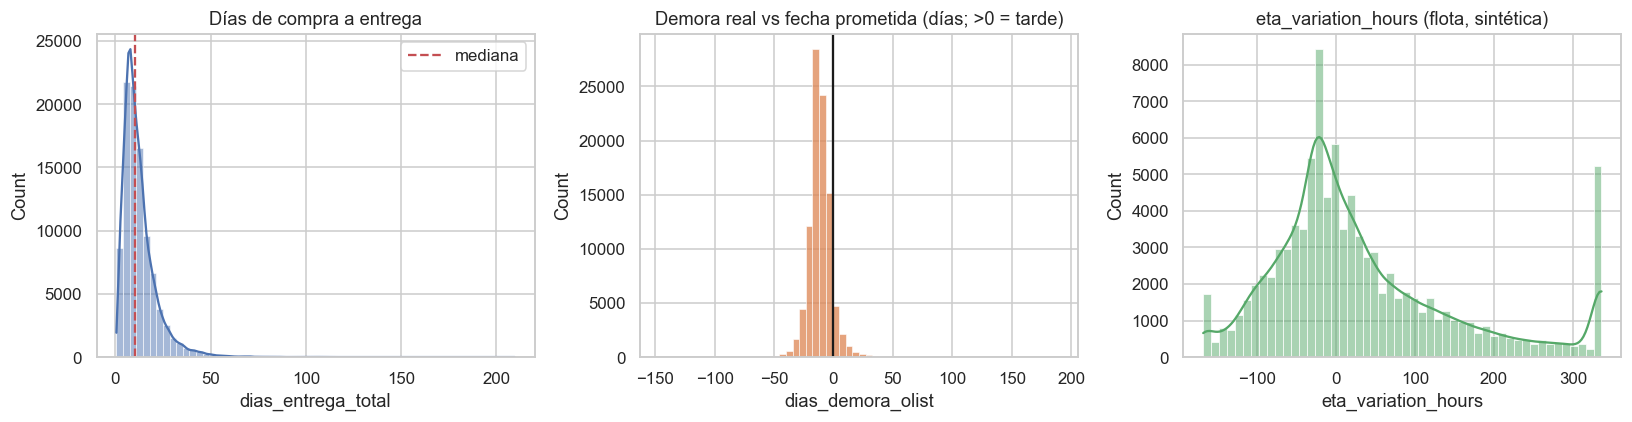

Entrega mediana 10.2 d | p95 29.3 d
% tarde (demora_olist): 8.1%  |  % delayed (delivery_status): 8.1%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.dias_entrega_total, bins=60, kde=True, ax=ax[0]); ax[0].set_title("Días de compra a entrega")
ax[0].axvline(df.dias_entrega_total.median(), c="r", ls="--", label="mediana"); ax[0].legend()
sns.histplot(df.dias_demora_olist, bins=60, ax=ax[1], color="C1"); ax[1].axvline(0, c="k"); ax[1].set_title("Demora real vs fecha prometida (días; >0 = tarde)")
sns.histplot(df.eta_variation_hours, bins=50, kde=True, ax=ax[2], color="C2"); ax[2].set_title("eta_variation_hours (flota, sintética)")
save("01_distribuciones_tiempos")
print(f"Entrega mediana {df.dias_entrega_total.median():.1f} d | p95 {df.dias_entrega_total.quantile(.95):.1f} d")
print(f"% tarde (demora_olist): {100*df.demora_olist.mean():.1f}%  |  % delayed (delivery_status): {100*(df.delivery_status=='delayed').mean():.1f}%")

**Lectura:** la entrega real es asimétrica a la derecha (cola larga de entregas muy tardías), por eso se usa **mediana y percentiles** además de la media. La demora real respecto de la fecha prometida es mayormente negativa (Olist promete con holgura); el problema está en la cola.

### Verificación: `delivery_status` vs `demora_olist`
En la flota, `delivery_status` se deriva de la demora real de Olist: coincide con `demora_olist` por construcción. Se verifica y, de aquí en adelante, se analiza solo `demora_olist`.

In [5]:
ct = pd.crosstab(df.demora_olist.astype(bool), df.delivery_status.astype(str), margins=True, margins_name="Total")
ct = ct[["on_time", "delayed", "Total"]]                    # orden explícito de columnas
ct.index = ["a tiempo (demora_olist)","tarde (demora_olist)","Total"]; ct.columns = ["on_time (delivery_status)","delayed (delivery_status)","Total"]
display(ct)
assert ((df.delivery_status == "delayed") == df.demora_olist).all(), "delivery_status debería coincidir con demora_olist; revisar el generador o la carga"
print("OK: delivery_status coincide con demora_olist (acuerdo 100 %). Se usa demora_olist en todo el notebook.")

,on_time (delivery_status),delayed (delivery_status),Total
a tiempo (demora_olist),88459,0,88459
tarde (demora_olist),0,7822,7822
Total,88459,7822,96281


OK: delivery_status coincide con demora_olist (acuerdo 100 %). Se usa demora_olist en todo el notebook.


## 3. Variables categóricas y segmentaciones

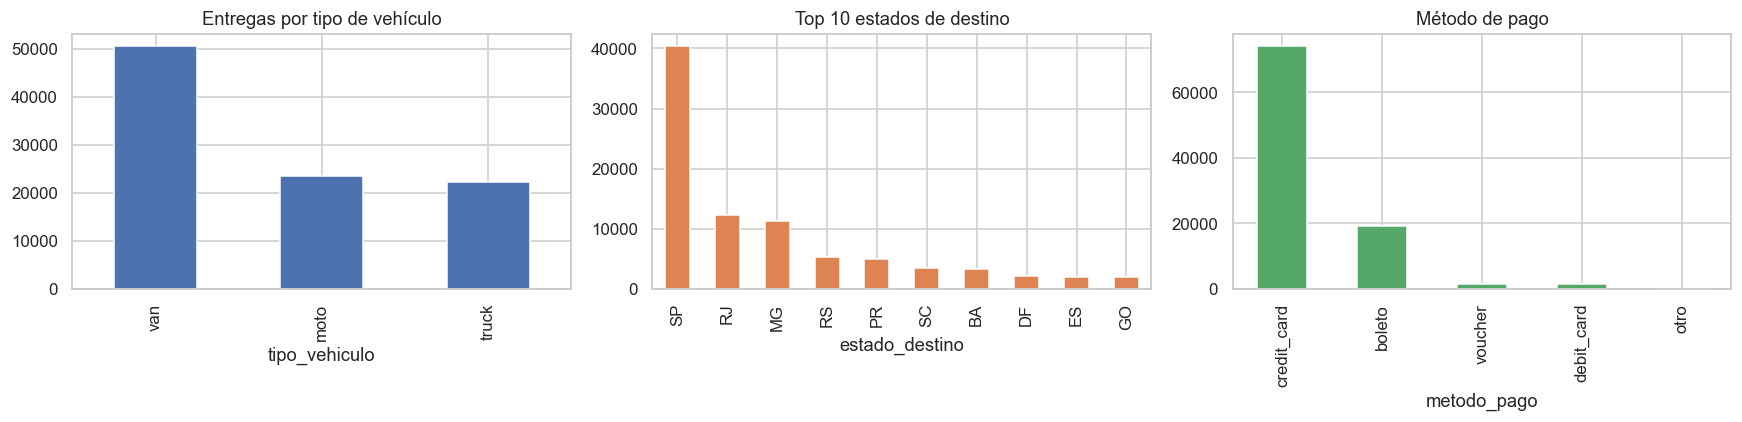

,entregas,demora_olist,dias_entrega,review,trafico,clima,riesgo
tipo_vehiculo,,,,,,,
moto,23526,0.074,9.42,4.154,5.00,0.495,6.891
truck,22216,0.089,11.13,4.119,4.99,0.503,7.042
van,50539,0.081,10.22,4.173,4.99,0.497,7.035


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.tipo_vehiculo.value_counts().plot.bar(ax=ax[0], color="C0"); ax[0].set_title("Entregas por tipo de vehículo")
df.estado_destino.value_counts().head(10).plot.bar(ax=ax[1], color="C1"); ax[1].set_title("Top 10 estados de destino")
df.metodo_pago.value_counts().plot.bar(ax=ax[2], color="C2"); ax[2].set_title("Método de pago")
save("02_categoricas")
seg = (df.groupby("tipo_vehiculo", observed=True)
         .agg(entregas=("order_id","count"), demora_olist=("demora_olist","mean"),
              dias_entrega=("dias_entrega_total","median"), review=("review_score","mean"),
              trafico=("traffic_congestion_level","mean"), clima=("weather_condition_severity","mean"),
              riesgo=("route_risk_level","mean")))
seg.round(3)

In [7]:
# ¿Difiere la demora real entre tipos de vehículo? chi² + V de Cramér
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = stats.chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2/(n*(min(t.shape)-1)))
t = pd.crosstab(df.tipo_vehiculo, df.demora_olist.astype(int))
print(f"demora_olist ~ tipo_vehiculo: chi² p={stats.chi2_contingency(t)[1]:.3g}  V Cramér={cramers_v(df.tipo_vehiculo, df.demora_olist.astype(int)):.3f}")
print("El tipo de vehículo se asigna por peso del producto: la diferencia no es causal. Tráfico, clima y riesgo no dependen del tipo (ver tabla anterior).")

demora_olist ~ tipo_vehiculo: chi² p=1.22e-08  V Cramér=0.019
El tipo de vehículo se asigna por peso del producto: la diferencia no es causal. Tráfico, clima y riesgo no dependen del tipo (ver tabla anterior).


In [8]:
top_est = df.estado_destino.value_counts().head(8).index
est = (df[df.estado_destino.isin(top_est)].groupby("estado_destino", observed=True)
       .agg(entregas=("order_id","count"), dias_entrega=("dias_entrega_total","median"),
            tarde_olist=("demora_olist","mean"), review=("review_score","mean"), flete=("flete_total","median"))
       .sort_values("tarde_olist", ascending=False))
est.round(3)

,entregas,dias_entrega,tarde_olist,review,flete
estado_destino,,,,,
BA,3252,16.910,0.14,3.930,22.07
RJ,12330,12.045,0.135,3.965,17.98
SC,3534,13.050,0.098,4.132,18.23
RS,5327,13.190,0.072,4.186,18.23
DF,2077,11.370,0.071,4.131,18.09
SP,40427,7.210,0.059,4.246,13.61
MG,11327,10.320,0.056,4.193,18.17
PR,4912,10.430,0.05,4.240,17.88


## 4. Factores operativos vs demora

In [9]:
from sklearn.metrics import roc_auc_score
fact = ["traffic_congestion_level","weather_condition_severity","route_risk_level","distance_km",
        "distancia_haversine_km","loading_unloading_time_h","driver_behavior_score","indice_fatiga","peso_total_g","flete_total"]
rows = []
for f in fact:
    d = df[[f,"eta_variation_hours","demora_olist","dias_demora_olist"]].dropna()
    y = d.demora_olist.astype(int)
    r_eta    = stats.spearmanr(d[f], d.eta_variation_hours)
    r_dolist = stats.spearmanr(d[f], d.dias_demora_olist)
    a, b = d.loc[y==1, f], d.loc[y==0, f]
    cohen = (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
    rows.append((f, r_eta.statistic, r_dolist.statistic, r_dolist.pvalue, a.mean()-b.mean(), cohen, roc_auc_score(y, d[f])))
corr = pd.DataFrame(rows, columns=["factor","rho_vs_eta_h","rho_vs_demora_real","p_real",
                                   "dif_medias_tarde_vs_no","d_cohen","auc_univariado"]).set_index("factor")
corr.round(4)

,rho_vs_eta_h,rho_vs_demora_real,p_real,dif_medias_tarde_vs_no,d_cohen,auc_univariado
factor,,,,,,
traffic_congestion_level,0.2715,0.3269,0.0000,3.3678,1.1010,0.7885
weather_condition_severity,0.2931,0.2523,0.0000,0.3348,1.0815,0.7881
route_risk_level,0.1285,0.1736,0.0000,2.3468,0.8914,0.7733
distance_km,-0.0323,-0.1780,0.0000,186.6956,0.2350,0.5628
distancia_haversine_km,-0.0322,-0.1788,0.0000,149.3198,0.2354,0.5629
loading_unloading_time_h,0.0272,-0.0058,0.0734,0.1237,0.0543,0.5141
driver_behavior_score,-0.0317,-0.0581,0.0000,-0.1247,-0.3607,0.4004
indice_fatiga,-0.0246,-0.0137,0.0000,-0.0936,-0.2773,0.4195
peso_total_g,0.0312,-0.0168,0.0000,287.7871,0.0570,0.5154


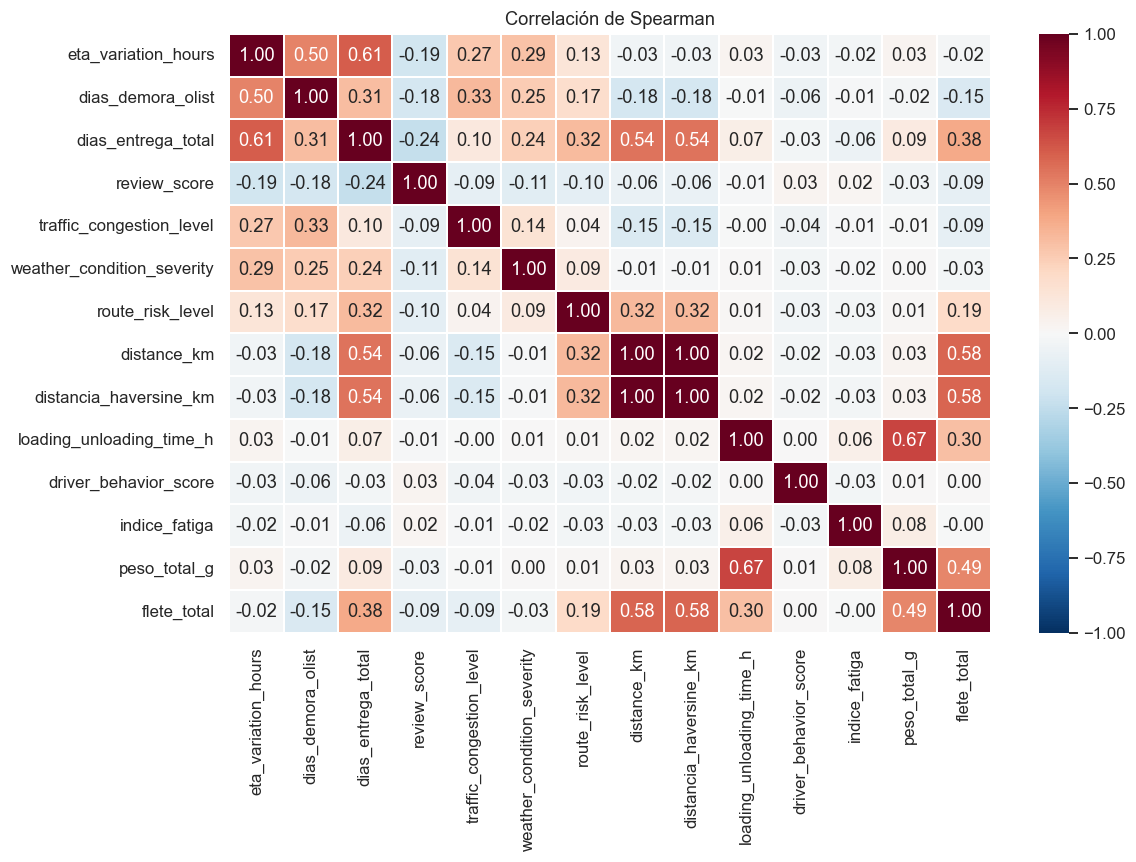

In [10]:
cm = df[["eta_variation_hours","dias_demora_olist","dias_entrega_total","review_score"]+fact].corr(method="spearman")
plt.figure(figsize=(11, 8)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.3)
plt.title("Correlación de Spearman"); save("03_correlaciones")

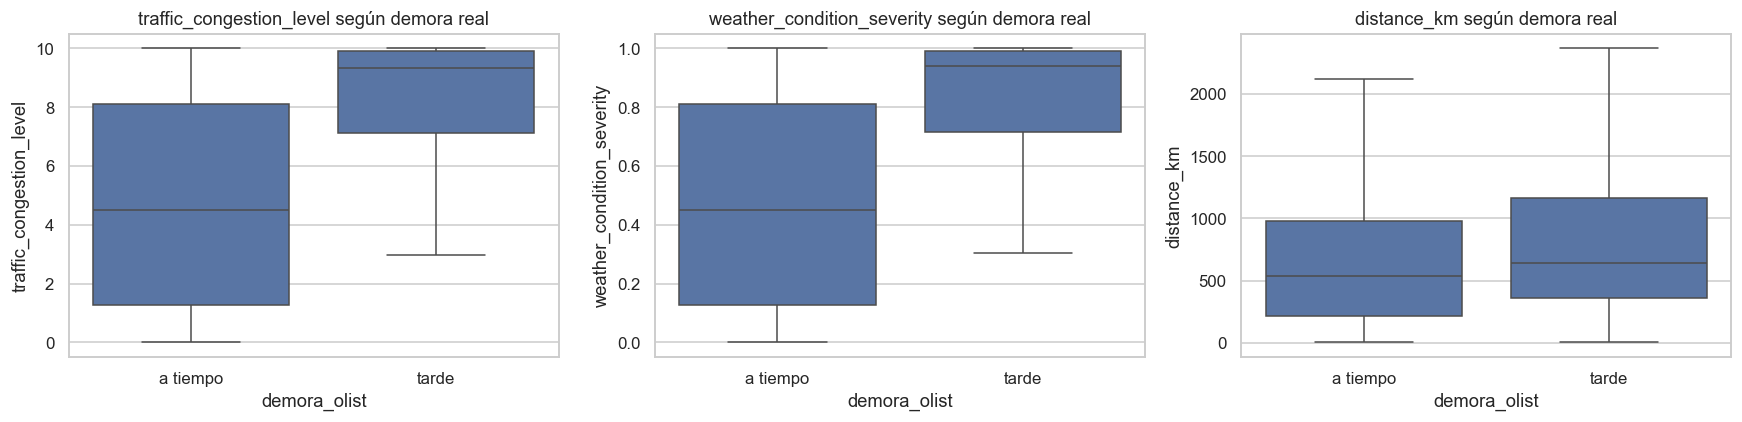

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, v in zip(ax, ["traffic_congestion_level","weather_condition_severity","distance_km"]):
    sns.boxplot(data=df, x="demora_olist", y=v, ax=a, showfliers=False); a.set_xticklabels(["a tiempo","tarde"]); a.set_title(f"{v} según demora real")
save("04_factores_vs_demora_real")

**Cómo leer este bloque.**
- `rho_vs_eta_h`: asociación con `eta_variation_hours` (deriva de las fechas reales y está acotada: ver sección 1). `rho_vs_demora_real`: asociación con los días de demora real respecto de la fecha prometida.
- `d_cohen` y `auc_univariado` miden cuánto separa cada variable a las entregas tarde de las puntuales (AUC 0,5 = nada; menor que 0,5 = relación inversa).
- Con ~96 000 filas casi toda correlación es significativa: **mirar el tamaño del efecto**; |rho| < 0,1 es despreciable en la práctica.
- **Variables reales** (distancia, flete, peso): su relación con la demora es un hallazgo sobre Olist. Distancia y flete correlacionan **negativamente** porque Olist promete plazos más largos para rutas largas.
- **Variables simuladas** (tráfico, clima, riesgo, conductor, fatiga, carga/descarga): su asociación fue **impuesta por el generador** (`EFFECTS`); describe el escenario simulado, no el mundo real. Carga/descarga no tiene vínculo por diseño y sirve de control.
- Implicancia para la Etapa 3: comparar predictores reales vs reales + simulados; la mejora del segundo conjunto es por construcción.

## 5. Demora y satisfacción del cliente

Órdenes con reseña: 95,636 (99.3%)


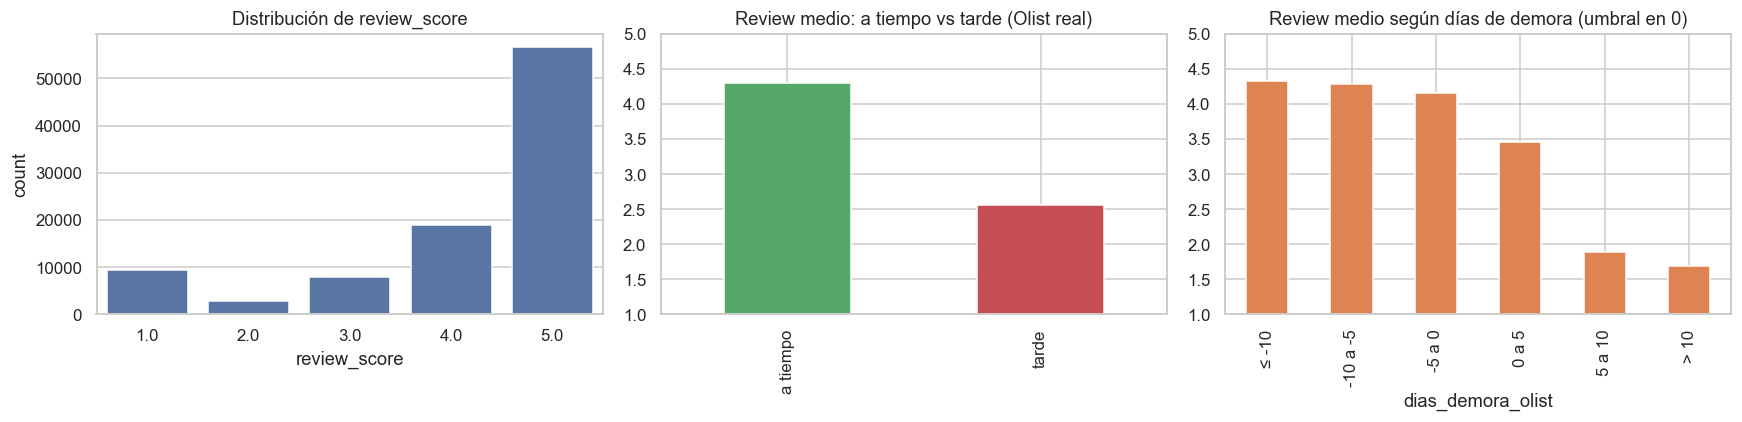

demora_olist: media tarde=2.56 vs a tiempo=4.29 | Mann-Whitney p=0 | d de Cohen=-1.21
Spearman(dias_demora_olist, review_score) = -0.177


In [12]:
rs = df.dropna(subset=["review_score"])
print(f"Órdenes con reseña: {len(rs):,} ({len(rs)/len(df):.1%})")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=rs, x="review_score", ax=ax[0], color="C0"); ax[0].set_title("Distribución de review_score")
g = rs.groupby("demora_olist", observed=True).review_score.mean(); g.index = ["a tiempo","tarde"]
g.plot.bar(ax=ax[1], color=["C2","C3"]); ax[1].set_ylim(1,5); ax[1].set_title("Review medio: a tiempo vs tarde (Olist real)")
tramos = pd.cut(rs.dias_demora_olist, [-np.inf,-10,-5,0,5,10,np.inf],
                labels=["≤ -10","-10 a -5","-5 a 0","0 a 5","5 a 10","> 10"])
rs.groupby(tramos, observed=True).review_score.mean().plot.bar(ax=ax[2], color="C1")
ax[2].set_ylim(1,5); ax[2].set_title("Review medio según días de demora (umbral en 0)")
save("05_demora_vs_review")
a = rs.loc[rs.demora_olist==True,"review_score"]; b = rs.loc[rs.demora_olist==False,"review_score"]
u = stats.mannwhitneyu(a, b); d = (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
print(f"demora_olist: media tarde={a.mean():.2f} vs a tiempo={b.mean():.2f} | Mann-Whitney p={u.pvalue:.3g} | d de Cohen={d:.2f}")
print(f"Spearman(dias_demora_olist, review_score) = {stats.spearmanr(rs.dias_demora_olist, rs.review_score).statistic:.3f}")

## 6. Análisis temporal y estacionalidad

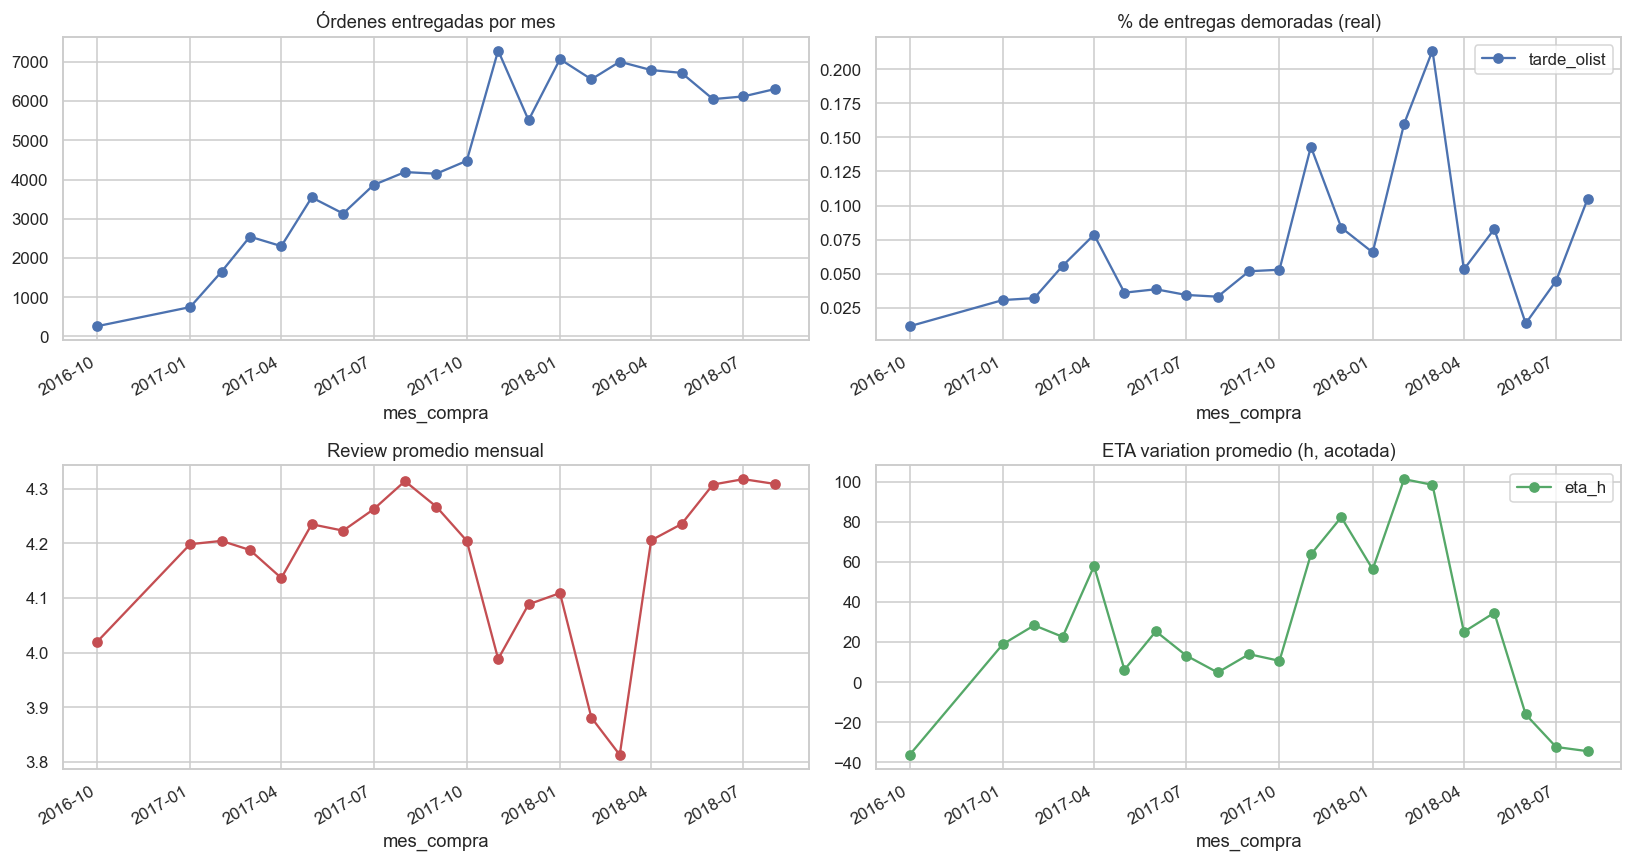

mes,1,2,3,4,5,6,7,8,9,10,11,12
tarde_olist,0.062,0.134,0.172,0.06,0.067,0.022,0.041,0.076,0.052,0.051,0.143,0.084
ordenes,7818,8206,9548,9094,10263,9184,9980,10497,4150,4739,7288,5514


In [13]:
m = (df.groupby("mes_compra").agg(ordenes=("order_id","count"), tarde_olist=("demora_olist","mean"),
         eta_h=("eta_variation_hours","mean"), review=("review_score","mean"), congestion=("traffic_congestion_level","mean"))
     .query("ordenes >= 200"))      # evita meses con muy pocas órdenes (ruido)
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
m.ordenes.plot(ax=ax[0,0], marker="o"); ax[0,0].set_title("Órdenes entregadas por mes")
m[["tarde_olist"]].plot(ax=ax[0,1], marker="o"); ax[0,1].set_title("% de entregas demoradas (real)")
m.review.plot(ax=ax[1,0], marker="o", color="C3"); ax[1,0].set_title("Review promedio mensual")
m[["eta_h"]].plot(ax=ax[1,1], marker="o", color="C2"); ax[1,1].set_title("ETA variation promedio (h, acotada)")
save("06_serie_mensual")
est_m = df.assign(mes=df.fecha_compra.dt.month).groupby("mes").agg(tarde_olist=("demora_olist","mean"), ordenes=("order_id","count"))
est_m.round(3).T

In [14]:
# Mantenimiento e incidentes vs demora real, por mes.
# Las columnas absolutas heredan el efecto del volumen de órdenes; las "_x1000" lo descuentan.
fm = pd.read_csv(ROOT/"output"/"flota_mes_tipo.csv", parse_dates=["mes"])
piv = fm.groupby("mes").agg(entregas=("entregas","sum"), correctivos=("mant_correctivos","sum"),
                            incidentes=("incidentes","sum"), costo=("costo_mant_brl","sum"))
piv["correctivos_x1000"] = 1000 * piv.correctivos / piv.entregas
piv["incidentes_x1000"]  = 1000 * piv.incidentes  / piv.entregas
piv = piv.join(m[["tarde_olist"]], how="inner")
rho = piv.corr(method="spearman")["tarde_olist"].drop("tarde_olist").round(3)
print(rho.to_string())
print("n meses =", len(piv), "→ con tan pocos puntos, estas correlaciones son orientativas, no concluyentes.")
print("Lectura: los incidentes dependen de la demora por diseño; los correctivos dependen del uso (volumen). "
      "Si 'correctivos_x1000' pierde la asociación, la de 'correctivos' era volumen.")

entregas             0.677
correctivos          0.579
incidentes           0.706
costo                0.660
correctivos_x1000   -0.091
incidentes_x1000     0.700
n meses = 21 → con tan pocos puntos, estas correlaciones son orientativas, no concluyentes.
Lectura: los incidentes dependen de la demora por diseño; los correctivos dependen del uso (volumen). Si 'correctivos_x1000' pierde la asociación, la de 'correctivos' era volumen.


## 7. Conductores y mantenimiento (tablas auxiliares)

        conductores  entregas  demora_olist  review
perfil                                             
alto             35     35583         0.061   4.188
bajo             41     40582         0.114   4.096
medio            19     20116         0.055   4.226
Conductor (n=95): behavior↔demora rho=-0.43 (p=1.2e-05) | behavior↔review rho=0.25 (p=0.015)
Ajustado por estado (n=95 conductores con ≥100 entregas): behavior↔razón rho=-0.47 (p=1.9e-06) | fatiga↔razón rho=0.54 (p=2e-08)


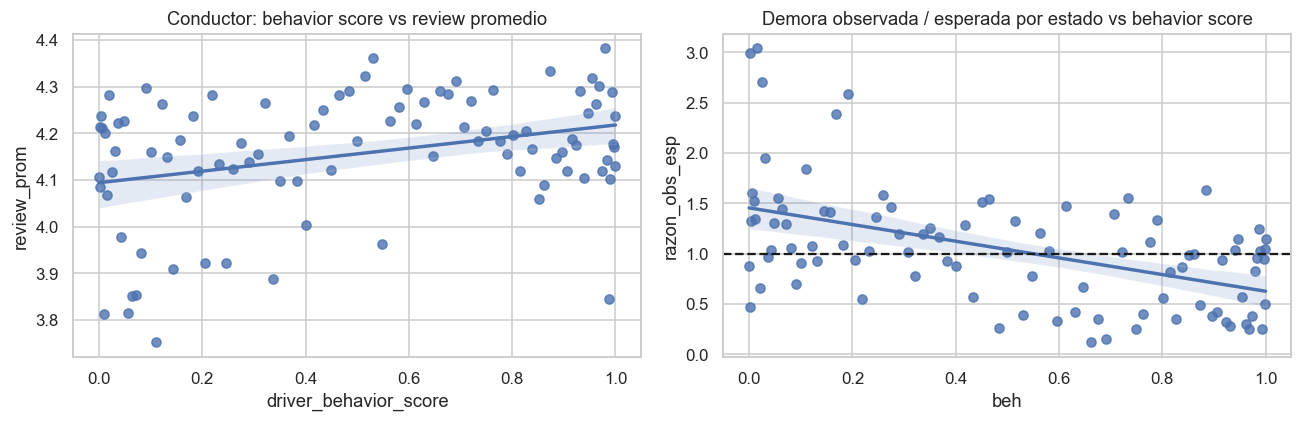

In [15]:
cd = pd.read_csv(ROOT/"output"/"conductores.csv")
print(cd.groupby("perfil").agg(conductores=("driver_id","count"), entregas=("entregas","sum"),
      demora_olist=("tasa_demora_olist","mean"), review=("review_prom","mean")).round(3))
r1 = stats.spearmanr(cd.driver_behavior_score, cd.tasa_demora_olist, nan_policy="omit")
r2 = stats.spearmanr(cd.driver_behavior_score, cd.review_prom, nan_policy="omit")
print(f"Conductor (n={len(cd)}): behavior↔demora rho={r1.statistic:.2f} (p={r1.pvalue:.2g}) | behavior↔review rho={r2.statistic:.2f} (p={r2.pvalue:.2g})")

# Efecto del conductor AJUSTADO por estado de destino: razón entre la demora observada y la esperada según su mezcla de estados
d = df.assign(tarde=df.demora_olist.astype(float))
d["esperado"] = d.groupby("estado_destino", observed=True)["tarde"].transform("mean")
g = d.groupby("driver_id").agg(obs=("tarde","mean"), esp=("esperado","mean"), n=("order_id","count"),
                               beh=("driver_behavior_score","first"), fat=("fatigue_score_avg","first"))
g["razon_obs_esp"] = g.obs / g.esp
g = g[g.n >= 100]
r3 = stats.spearmanr(g.beh, g.razon_obs_esp); r4 = stats.spearmanr(g.fat, g.razon_obs_esp)
print(f"Ajustado por estado (n={len(g)} conductores con ≥100 entregas): behavior↔razón rho={r3.statistic:.2f} (p={r3.pvalue:.2g}) | fatiga↔razón rho={r4.statistic:.2f} (p={r4.pvalue:.2g})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=cd, x="driver_behavior_score", y="review_prom", ax=ax[0]); ax[0].set_title("Conductor: behavior score vs review promedio")
sns.regplot(data=g.reset_index(), x="beh", y="razon_obs_esp", ax=ax[1]); ax[1].axhline(1, c="k", ls="--")
ax[1].set_title("Demora observada / esperada por estado vs behavior score")
save("07_conductor_review")

## 8. Conclusiones del EDA → insumos para Etapa 3
Documento completo: `docs/conclusiones_eda.md`. Resumen:

| # | Hallazgo | Evidencia | Implicancia |
|---|---|---|---|
| 1 | Entrega real asimétrica, cola larga | mediana 10,2 d, p95 29,3 d | Usar mediana/percentiles; considerar log |
| 2 | `delivery_status` replica la demora real | acuerdo 100 % con `demora_olist` | Usar `demora_olist` como objetivo del Modelo 2 |
| 3 | La demora real destruye la satisfacción | reseña 2,56 vs 4,29; d = -1,21 | KPI de satisfacción y justificación del problema |
| 4 | El destino concentra el problema | BA 14,0 %, RJ 13,5 % vs SP 5,9 %, PR 5,0 % | Segmentación principal del dashboard |
| 5 | La distancia no aumenta la demora real | rho haversine = -0,18; flete = -0,15 | Olist promete más plazo a rutas largas |
| 6 | Factores simulados asociados a la demora (por diseño) | AUC univariado: tráfico 0,789, clima 0,788, riesgo 0,773; d de Cohen 1,10 / 1,08 / 0,89 | Escenario simulado; no evidencia empírica. Un modelo con ellos tendrá un AUC alto por construcción |
| 7 | Conductor: efecto por conductor, no por entrega | por entrega rho = -0,06; por conductor -0,43; ajustado por estado -0,47 (p = 1,9e-6); fatiga +0,54 | Declarar por diseño; el ajuste por estado no cambia la conclusión |
| 8 | Mantenimiento/incidentes vs demora mensual | correctivos +0,58 → -0,09 por 1.000 entregas; incidentes +0,71 → +0,70 | Correctivos: efecto del volumen. Incidentes: asociados por construcción |
| 9 | `eta_variation_hours` censurada | 5,1 % en el techo y 1,3 % en el piso; p95 = 336 | No usarla como objetivo |

**Variables a llevar a Etapa 3:** ver columnas del dataset; excluir de los predictores todo lo que se conoce solo *después* de la entrega (`dias_entrega_total`, `dias_transito`, `dias_hasta_despacho`, `dias_demora_olist`, `eta_variation_hours`, `delivery_status`, `review_score`, `resena_negativa`, `n_incidentes`, `horas_impacto_incidentes`) para evitar **fuga de información (data leakage)**. Tráfico, clima y riesgo se generan condicionados al resultado: declararlos como covariables simuladas.